In [4]:
import sys
import os
import json
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# 1. Point Python to the src/ directory and import your custom modules
sys.path.append(os.path.abspath('../'))
from src.models.sql_models import SQLCNN
from src.utils.data_helpers import encode_query

# 2. Load the vocabulary you saved earlier
with open('../data/processed/sql_word2idx.json', 'r') as f:
    word2idx = json.load(f)

# 3. Recreate the exact same Test Set
# We use random_state=42 to guarantee we extract the exact same 15% we used during training
df = pd.read_csv('../data/raw/Modified_SQL_Dataset.csv').dropna()
X = df['Query'].astype(str).values
y = df['Label'].values
_, X_test, _, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

# 4. Encode the queries and create the test DataLoader
X_test_encoded = np.array([encode_query(q, word2idx, max_length=100) for q in X_test])
test_dataset = TensorDataset(torch.tensor(X_test_encoded, dtype=torch.long), torch.tensor(y_test, dtype=torch.float32))
test_loader = DataLoader(test_dataset, shuffle=False, batch_size=32)

Model loaded successfully. Running inference on unseen Test Set...

--- Final Test Metrics ---
Accuracy:  0.9972 (Overall correctness)
Precision: 0.9994 (When it flags an attack, how often is it right?)
Recall:    0.9930 (Out of all real attacks, how many did it catch?)
F1-Score:  0.9962 (Balance between Precision and Recall)


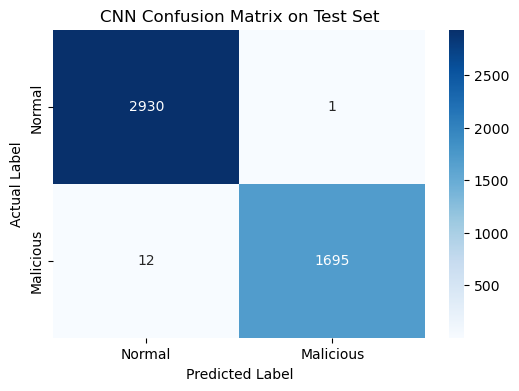

In [5]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Setup device and initialize a fresh model architecture
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
vocab_size = len(word2idx)
test_model = SQLCNN(vocab_size=vocab_size).to(device)

# 2. Load the best saved weights into the model
# weights_only=True is a security best practice in modern PyTorch
test_model.load_state_dict(torch.load('SQL_CNN_best.pth', map_location=device, weights_only=True))
test_model.eval() # Lock the model for testing (disables dropout layers)

print("Model loaded successfully. Running inference on unseen Test Set...")

all_predictions = []
all_true_labels = []

# 3. Pass the test_loader data through the model without calculating gradients
with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        
        # Get raw outputs and convert to 0 or 1 predictions
        raw_logits = test_model(batch_x).squeeze(1)
        predictions = torch.round(torch.sigmoid(raw_logits)).cpu().numpy()
        
        all_predictions.extend(predictions)
        all_true_labels.extend(batch_y.numpy())

# 4. Calculate Final Metrics
acc = accuracy_score(all_true_labels, all_predictions)
prec = precision_score(all_true_labels, all_predictions)
rec = recall_score(all_true_labels, all_predictions)
f1 = f1_score(all_true_labels, all_predictions)

print("\n--- Final Test Metrics ---")
print(f"Accuracy:  {acc:.4f} (Overall correctness)")
print(f"Precision: {prec:.4f} (When it flags an attack, how often is it right?)")
print(f"Recall:    {rec:.4f} (Out of all real attacks, how many did it catch?)")
print(f"F1-Score:  {f1:.4f} (Balance between Precision and Recall)")

# 5. Visualize the Confusion Matrix
cm = confusion_matrix(all_true_labels, all_predictions)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Malicious'], yticklabels=['Normal', 'Malicious'])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('CNN Confusion Matrix on Test Set')
plt.show()